# Multi-Fidelity NN Comparison: HF Sample Sweep (2D)

Sweeps the number of HF samples from 20 to 200 for `SurrogateModels.mfsnn.MultiFidelityNN` on the 2D test function (`PeaksShifted2`), with 800 LF samples.

- **LF network:** one `MLPNetwork` (`[30, 30, 10]`) is trained on the LF samples and shared by every run, so the runs differ only in the HF samples and the MF network.
- **MF network:** the composite's nonlinear path is `[16, 16, 16]` with weight decay 1e-6, the best size from the size sweep in `CompositeNN_2DSpotCheck.ipynb`.
- **HF samples:** each count is a Latin hypercube sample, drawn with 3 sampling seeds. The sets aren't nested: the 40-sample set doesn't contain the 20-sample set.
- **Runs:** each HF sample set is trained from 3 seeds for the MF network's initial weights, so there are 9 runs per HF count (90 in total). This separates the spread from where the HF samples fall from the spread from the starting weights.

The composites train in parallel on the CPU, one thread each, using `generate_mf_nn_hf_sweep` in `examples/multi_fidelity_nn_helpers.py`. It fits the same composite as `MultiFidelityNN` with `lf_model` passed in. The sweep takes about 20 minutes.

**Output:** `mf_nn_hf_sweep_2d_sampling.csv` has the columns `points_lf, points_hf, hf_sample_seed, seed, test_rmse, train_rmse, training_time`, where `seed` is the MF network's seed and RMSE is in original units. `training_time` covers the composite only. Rerunning appends to the file.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import multi_fidelity_nn_helpers as mf_nn_helpers
from SurrogateModels import mfsnn

### Data

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()

n_lf = 800
hf_points = range(20, 201, 20)
hf_sample_seeds = [0, 1, 2]
seed = 0

# One LF sample set and LF network are shared by every run
X_lf = my_function.sample_random(n_lf, seed=seed)
y_lf = my_function.low_fidelity(X_lf)

# Shared test locations, evaluated with each fidelity
X_test = my_function.sample_random(1000, seed=1234)
y_lf_test = my_function.low_fidelity(X_test)
y_hf_test = my_function.high_fidelity(X_test)

### LF network

In [3]:
settings = dict(
    lf_nn_dim=[30, 30, 10],
    hf_nl_nn_dim=[16, 16, 16],
    epochs_lf=30000,
    epochs_mf=30000,
    lr_lf=1e-4,
    wd_lf=1e-6,
    lr_mf=1e-4,
    wd_mf=1e-6,
    mf_seeds=3,
)

t0 = time.perf_counter()
lf_nn = mfsnn.MLPNetwork(
    X_lf, y_lf, X_test, y_lf_test,
    hidden_layer_size=settings["lf_nn_dim"],
    epochs=settings["epochs_lf"],
    learning_rate=settings["lr_lf"],
    weight_decay=settings["wd_lf"],
    scale_input=True,
    scale_output=True,
    bounds=my_function.bounds,
)
lf_train_time = time.perf_counter() - t0

lf_error = float(lf_nn.model_error(X_test, y_lf_test))
print(f"Train time: {lf_train_time:.1f}s")
print(f"LF fit test RMSE (vs LF function): {lf_error:.4g}")

Train time: 147.7s
LF fit test RMSE (vs LF function): 0.006252


### HF sample sweep

In [4]:
t0 = time.perf_counter()
sweep_results = mf_nn_helpers.generate_mf_nn_hf_sweep(
    lf_nn,
    my_function,
    y_lf,
    X_test,
    y_hf_test,
    hf_points=hf_points,
    seeds=settings["mf_seeds"],
    hf_sample_seeds=hf_sample_seeds,
    hf_nl_nn_dim=settings["hf_nl_nn_dim"],
    epochs_mf=settings["epochs_mf"],
    lr_mf=settings["lr_mf"],
    wd_mf=settings["wd_mf"],
    n_workers=8,
    output_file="mf_nn_hf_sweep_2d_sampling.csv",
)
print(f"Sweep time: {(time.perf_counter() - t0) / 60:.1f} min")

1/90 :: hf points 20 :: sampling seed 0 :: seed 0 :: test 1.114 :: train 4.171e-06


2/90 :: hf points 20 :: sampling seed 0 :: seed 1 :: test 1.103 :: train 3.952e-05
3/90 :: hf points 20 :: sampling seed 0 :: seed 2 :: test 0.8792 :: train 7.981e-05


4/90 :: hf points 40 :: sampling seed 0 :: seed 2 :: test 0.5828 :: train 1.961e-06


5/90 :: hf points 60 :: sampling seed 0 :: seed 0 :: test 0.7051 :: train 0.002967
6/90 :: hf points 60 :: sampling seed 0 :: seed 1 :: test 0.5375 :: train 0.003281


7/90 :: hf points 40 :: sampling seed 0 :: seed 1 :: test 0.5996 :: train 0.0002169


8/90 :: hf points 40 :: sampling seed 0 :: seed 0 :: test 0.5145 :: train 8.405e-05


... (74 outputs left out)

88/90 :: hf points 200 :: sampling seed 2 :: seed 0 :: test 0.06152 :: train 0.008505


89/90 :: hf points 200 :: sampling seed 2 :: seed 1 :: test 0.05655 :: train 0.006862


90/90 :: hf points 200 :: sampling seed 2 :: seed 2 :: test 0.05438 :: train 0.007152


Sweep time: 37.0 min


### Results

Test RMSE against the HF function and train RMSE on the HF samples, both in original units. Each small marker is one run. The thin colored lines are the median of the 3 MF seeds for each HF sample set, and the thick black line is the median of all 9 runs at each count.

The table at the end splits the spread at each count into two parts, both as standard deviations of log10(test RMSE), because the errors change by an order of magnitude across the sweep:
- **Between sample sets:** the spread of the 3 sample sets' mean errors, which shows how much where the HF samples fall matters.
- **Within a sample set:** the spread across MF seeds on the same samples, averaged over the 3 sets, which shows how much the starting weights matter.

For reference, the diamonds are the HF-only `MLPNetwork` runs at 200 samples or fewer from `nn_model_comparison_2d.csv` (the single-fidelity sweep). They use different test points and the single-fidelity network settings, so treat them as a rough comparison.

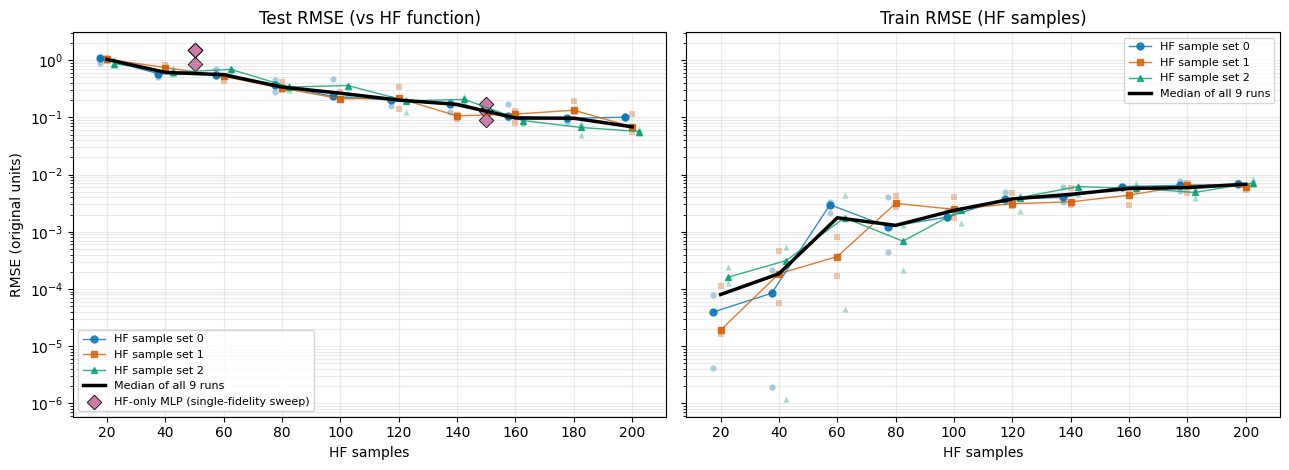

LF fit test RMSE: 0.006252

Median test RMSE over the MF seeds, by HF samples and HF sample set
            set 0   set 1   set 2  all runs
points_hf                                  
20         1.1027  1.0340  0.8724    1.0340
40         0.5828  0.7458  0.6124    0.6124
60         0.5582  0.5202  0.6913    0.5582
80         0.3728  0.3234  0.3390    0.3390
100        0.2330  0.2121  0.3612    0.2647
120        0.2008  0.2152  0.1945    0.2008
140        0.1689  0.1062  0.2065    0.1689
160        0.1045  0.1144  0.0879    0.0974
180        0.0968  0.1335  0.0666    0.0968
200        0.1005  0.0684  0.0565    0.0684

Spread of log10(test RMSE), as standard deviations
           between sample sets  within a sample set
points_hf                                          
20                       0.031                0.046
40                       0.058                0.043
60                       0.065                0.050
80                       0.017                0.074
100         

In [5]:
runs = pd.DataFrame(sweep_results)[mf_nn_helpers.HF_SWEEP_HEADER].sort_values(["points_hf", "hf_sample_seed", "seed"])
medians = runs.groupby("points_hf")[["test_rmse", "train_rmse"]].median()
set_medians = runs.groupby(["hf_sample_seed", "points_hf"])[["test_rmse", "train_rmse"]].median()
set_styles = dict(zip(hf_sample_seeds, [("#0072B2", "o"), ("#D55E00", "s"), ("#009E73", "^")]))
offsets = dict(zip(hf_sample_seeds, [-2.5, 0.0, 2.5]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, column, title in [
    (axes[0], "test_rmse", "Test RMSE (vs HF function)"),
    (axes[1], "train_rmse", "Train RMSE (HF samples)"),
]:
    for sample_seed, (color, marker) in set_styles.items():
        group = runs[runs["hf_sample_seed"] == sample_seed]
        line = set_medians.loc[sample_seed][column]
        ax.scatter(group["points_hf"] + offsets[sample_seed], group[column], s=20, color=color, marker=marker,
                   alpha=0.35, linewidth=0)
        ax.plot(line.index + offsets[sample_seed], line.values, color=color, marker=marker, markersize=5,
                linewidth=1, alpha=0.8, label=f"HF sample set {sample_seed}")
    ax.plot(medians.index, medians[column], color="black", linewidth=2.5,
            label=f"Median of all {len(hf_sample_seeds) * settings['mf_seeds']} runs")
    ax.set_yscale("log")
    ax.set_xticks(list(hf_points))
    ax.set_title(title)
    ax.set_xlabel("HF samples")
    ax.grid(True, which="both", alpha=0.25)

reference_file = "nn_model_comparison_2d.csv"
if os.path.exists(reference_file):
    hf_only = pd.read_csv(reference_file)
    hf_only = hf_only[hf_only["points"] <= max(hf_points)]
    axes[0].scatter(hf_only["points"], hf_only["model_error"], s=55, color="#CC79A7", marker="D",
                    edgecolor="black", linewidth=0.6, label="HF-only MLP (single-fidelity sweep)")

axes[0].set_ylabel("RMSE (original units)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"LF fit test RMSE: {lf_error:.4g}")
print()
print("Median test RMSE over the MF seeds, by HF samples and HF sample set")
table = runs.pivot_table(index="points_hf", columns="hf_sample_seed", values="test_rmse", aggfunc="median")
table.columns = [f"set {c}" for c in table.columns]
print(table.assign(**{"all runs": medians["test_rmse"]}).round(4).to_string())
print()

# Spread of log10(test RMSE) between sample sets and within a sample set
runs["log_test"] = np.log10(runs["test_rmse"])
by_set = runs.groupby(["points_hf", "hf_sample_seed"])["log_test"]
spread = pd.DataFrame({
    "between sample sets": by_set.mean().groupby("points_hf").std(),
    "within a sample set": by_set.std().groupby("points_hf").mean(),
})
print("Spread of log10(test RMSE), as standard deviations")
print(spread.round(3).to_string())
print(f"Mean over HF counts: between {spread.iloc[:, 0].mean():.3f}, within {spread.iloc[:, 1].mean():.3f}")
print()
print("Median train RMSE by HF samples")
print(medians["train_rmse"].round(5).to_string())